# Klasifikasi Tutupan Lahan Jawa Timur dengan Random Forest

## Business Understanding
### Permasalahan
Informasi mengenai persebaran tutupan lahan diperlukan untuk memahami kondisi permukaan bumi di Jawa Timur. Pengamatan secara langsung terhadap seluruh wilayah membutuhkan waktu dan biaya, sehingga citra satelit dapat dimanfaatkan untuk memperoleh gambaran wilayah secara lebih luas.

### Tujuan utama
Membuat peta tutupan permukaan bumi di Jawa Timur menggunakan citra satelit Sentinel-2 dan metode Random Forest untuk mengelompokkan piksel citra menjadi lima kelas tutupan lahan.

### Hasil yang diharapkan
Peta tematik yang menunjukkan lokasi dan persebaran bangunan, lahan pertanian, badan air, hutan, dan hutan mangrove, disertai evaluasi akurasi model dan perkiraan luas setiap kelas.

### kelas yang akan dipetakan

**Kelas:** bangunan, lahan pertanian, badan air, hutan, dan mangrove.  
**Band utama sesuai instruksi:** B8A, B11, B04.  
**Algoritma utama:** Random Forest.  
**Platform:** Google Colab.

### Apa tujuan penggunaan citra satelit dan Random Forest?
- Citra satelit Sentinel-2: menyediakan informasi spektral permukaan bumi yang dapat digunakan untuk membedakan karakteristik tutupan lahan.
- Band B8A, B11, dan B04: menyediakan informasi spektral yang digunakan sebagai fitur masukan model. Band-band tersebut diselaraskan pada grid beresolusi 20 meter.
- Random Forest: mempelajari pola dari sampel yang sudah memiliki label kelas, kemudian memprediksi kelas pada piksel citra lainnya.
- Evaluasi model: mengukur seberapa baik hasil prediksi sesuai dengan label sampel pengujian.
- Peta hasil klasifikasi: menyajikan hasil prediksi secara geografis agar persebaran tutupan lahan lebih mudah dipahami.

## 1. Instalasi library

In [1]:
!pip -q install rasterio geopandas shapely scikit-learn matplotlib pandas

## 2. Import library

In [2]:
import os, zipfile, json, glob, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.warp import reproject, Resampling, calculate_default_transform
from rasterio.features import geometry_mask, shapes
from rasterio.plot import show
from shapely.geometry import shape, mapping
from shapely.validation import make_valid
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, accuracy_score, classification_report,
    cohen_kappa_score, ConfusionMatrixDisplay, f1_score
)
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display

warnings.filterwarnings("ignore")
os.makedirs("/content/landcover_output", exist_ok=True)
print("Library siap.")

Library siap.


unggah ZIP band dan data mentah GeoJSON

In [7]:
from google.colab import files
import os
import zipfile
import glob

uploaded_zip = files.upload()

zip_candidates = [
    n for n in uploaded_zip
    if n.lower().endswith(".zip")
]

if not zip_candidates:
    raise ValueError("Unggah file ZIP raster Sentinel-2.")

ZIP_PATH = "/content/" + zip_candidates[0]

print("ZIP berhasil diunggah:", ZIP_PATH)

Saving Browser_images.zip to Browser_images (2).zip
ZIP berhasil diunggah: /content/Browser_images (2).zip


In [8]:
uploaded_samples = files.upload()

geojson_candidates = [
    n for n in uploaded_samples
    if n.lower().endswith(".geojson")
]

if not geojson_candidates:
    raise ValueError("Unggah file jatim.geojson.")

SAMPLES_PATH = "/content/" + geojson_candidates[0]

print("GeoJSON berhasil diunggah:", SAMPLES_PATH)

Saving jatim.geojson to jatim.geojson
GeoJSON berhasil diunggah: /content/jatim.geojson


In [9]:
DATA_DIR = "/content/sentinel_bands"
os.makedirs(DATA_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(DATA_DIR)

raster_files = (
    glob.glob(DATA_DIR + "/**/*.tif", recursive=True)
    + glob.glob(DATA_DIR + "/**/*.tiff", recursive=True)
)

print("Jumlah raster ditemukan:", len(raster_files))

for path in raster_files:
    print(os.path.basename(path))

Jumlah raster ditemukan: 5
2023-02-07-00_00_2023-02-07-23_59_Sentinel-2_L2A_B03_(Raw).tiff
2023-02-07-00_00_2023-02-07-23_59_Sentinel-2_L2A_B11_(Raw).tiff
2023-02-07-00_00_2023-02-07-23_59_Sentinel-2_L2A_B04_(Raw).tiff
2023-02-07-00_00_2023-02-07-23_59_Sentinel-2_L2A_True_color.tiff
2023-02-07-00_00_2023-02-07-23_59_Sentinel-2_L2A_B8A_(Raw).tiff


In [10]:
if not os.path.exists(ZIP_PATH):
    raise FileNotFoundError("ZIP raster tidak ditemukan.")

if not os.path.exists(SAMPLES_PATH):
    raise FileNotFoundError("jatim.geojson tidak ditemukan.")

if not raster_files:
    raise ValueError(
        "Tidak ditemukan raster GeoTIFF. "
        "Periksa isi ZIP yang diunggah."
    )

print("Semua file berhasil disiapkan.")
print("Raster ZIP :", ZIP_PATH)
print("GeoJSON    :", SAMPLES_PATH)
print("Jumlah raster:", len(raster_files))

Semua file berhasil disiapkan.
Raster ZIP : /content/Browser_images (2).zip
GeoJSON    : /content/jatim.geojson
Jumlah raster: 5


## 4. Pemeriksaan band raster

In [11]:
# Deteksi nama band dari nama file. Jika nama file berbeda, edit BAND_HINTS.
BAND_HINTS = {
    "B8A": ["B8A", "B08A"],
    "B11": ["B11"],
    "B04": ["B04", "B4_"]
}

band_paths = {}
for band, hints in BAND_HINTS.items():
    matches = [
        p for p in raster_files
        if any(h.lower() in os.path.basename(p).lower() for h in hints)
        and "true_color" not in os.path.basename(p).lower()
    ]
    if matches:
        band_paths[band] = matches[0]

print("Band terdeteksi:")
for k, v in band_paths.items():
    print(k, "->", os.path.basename(v))

missing = [b for b in ["B8A", "B11", "B04"] if b not in band_paths]
if missing:
    raise FileNotFoundError(
        f"Band berikut belum ditemukan: {missing}. "
        "Pastikan mengunduh raw band B8A, B11, dan B04; bukan hanya True Color."
    )

for band, path in band_paths.items():
    with rasterio.open(path) as src:
        print(
            band, "| CRS:", src.crs, "| ukuran:", src.width, "x", src.height,
            "| resolusi:", src.res, "| nodata:", src.nodata, "| bounds:", src.bounds
        )

Band terdeteksi:
B8A -> 2023-02-07-00_00_2023-02-07-23_59_Sentinel-2_L2A_B8A_(Raw).tiff
B11 -> 2023-02-07-00_00_2023-02-07-23_59_Sentinel-2_L2A_B11_(Raw).tiff
B04 -> 2023-02-07-00_00_2023-02-07-23_59_Sentinel-2_L2A_B04_(Raw).tiff
B8A | CRS: EPSG:4326 | ukuran: 2364 x 2500 | resolusi: (0.00030429018612521043, 0.00030147079999999954) | nodata: None | bounds: BoundingBox(left=112.151054, bottom=-8.082351, right=112.870396, top=-7.328674)
B11 | CRS: EPSG:4326 | ukuran: 2364 x 2500 | resolusi: (0.00030429018612521043, 0.00030147079999999954) | nodata: None | bounds: BoundingBox(left=112.151054, bottom=-8.082351, right=112.870396, top=-7.328674)
B04 | CRS: EPSG:4326 | ukuran: 2364 x 2500 | resolusi: (0.00030429018612521043, 0.00030147079999999954) | nodata: None | bounds: BoundingBox(left=112.151054, bottom=-8.082351, right=112.870396, top=-7.328674)


## 5. Membaca AOI dan sampel GeoJSON

In [14]:
import geopandas as gpd

test_data = gpd.read_file(SAMPLES_PATH)

print("Jumlah data uji:", len(test_data))
print("CRS:", test_data.crs)
print("Kolom:", test_data.columns.tolist())

display(test_data.head())

if test_data.crs is None:
    raise ValueError("CRS data uji tidak ditemukan.")

test_data = test_data.to_crs("EPSG:4326")

Jumlah data uji: 250
CRS: EPSG:4326
Kolom: ['no', 'type', 'geometry']


,no,type,geometry
0,1,Mangrove,"POLYGON ((112.83105 -7.38411, 112.83078 -7.384..."
1,2,Mangrove,"POLYGON ((112.83852 -7.33852, 112.8382 -7.3389..."
2,3,Mangrove,"POLYGON ((112.83801 -7.34006, 112.83775 -7.340..."
3,4,Mangrove,"POLYGON ((112.83659 -7.35015, 112.83609 -7.351..."
4,5,Mangrove,"POLYGON ((112.83477 -7.38195, 112.83494 -7.382..."


## 6. Normalisasi label menjadi lima kelas

In [18]:
import geopandas as gpd
from shapely import make_valid

# Baca data uji dari jatim.geojson
samples = gpd.read_file(SAMPLES_PATH)

if samples.crs is None:
    raise ValueError("CRS jatim.geojson tidak ditemukan.")

# Samakan CRS
samples = samples.to_crs("EPSG:4326")

# Kolom yang berisi label kelas
CLASS_COLUMN = "type"

LABEL_MAP = {
    "bangunan": "bangunan",
    "bagunan": "bangunan",
    "built up": "bangunan",
    "built-up": "bangunan",
    "building": "bangunan",

    "lahan pertanian": "lahan_pertanian",
    "lahan_pertanian": "lahan_pertanian",
    "pertanian": "lahan_pertanian",
    "farmland": "lahan_pertanian",
    "farm land": "lahan_pertanian",
    "sawah": "lahan_pertanian",

    "water body": "badan_air",
    "waterbody": "badan_air",
    "badan air": "badan_air",
    "badan_air": "badan_air",
    "perairan": "badan_air",
    "laut": "badan_air",
    "danau": "badan_air",

    "hutan": "hutan",
    "forest": "hutan",

    "mangrove": "mangrove",
    "hutan mangrove": "mangrove"
}

CLASSES = [
    "bangunan",
    "lahan_pertanian",
    "badan_air",
    "hutan",
    "mangrove"
]

CLASS_TO_ID = {
    name: i + 1 for i, name in enumerate(CLASSES)
}

ID_TO_CLASS = {
    v: k for k, v in CLASS_TO_ID.items()
}

# Periksa kolom label
if CLASS_COLUMN not in samples.columns:
    raise ValueError(
        f"Kolom '{CLASS_COLUMN}' tidak ditemukan. "
        f"Kolom tersedia: {samples.columns.tolist()}"
    )

# Normalisasi label
samples["label_asli"] = (
    samples[CLASS_COLUMN]
    .astype("string")
    .str.strip()
    .str.lower()
)

samples["class_name"] = samples["label_asli"].map(LABEL_MAP)

# Periksa label yang belum dikenali
unknown = sorted(
    samples.loc[
        samples["class_name"].isna(),
        "label_asli"
    ].dropna().unique().tolist()
)

if unknown:
    print("Label belum dipetakan:", unknown)

# Hapus data tanpa label dan geometri
samples = samples.dropna(
    subset=["class_name", "geometry"]
).copy()

# Pertahankan poligon
samples = samples[
    samples.geometry.geom_type.isin(
        ["Polygon", "MultiPolygon"]
    )
].copy()

# Perbaiki geometri yang tidak valid
samples["geometry"] = samples.geometry.apply(
    lambda g: make_valid(g) if not g.is_valid else g
)

samples = samples[
    ~samples.geometry.is_empty
].copy()

samples = samples[
    samples["class_name"].isin(CLASSES)
].copy()

# Tampilkan jumlah sampel setiap kelas
print("Jumlah sampel valid:", len(samples))
print("\nJumlah sampel per kelas:")

display(
    samples["class_name"]
    .value_counts()
    .reindex(CLASSES, fill_value=0)
    .to_frame("jumlah_poligon")
)

Jumlah sampel valid: 249

Jumlah sampel per kelas:


,jumlah_poligon
class_name,
bangunan,50
lahan_pertanian,49
badan_air,50
hutan,50
mangrove,50


## 7. Visualisasi batas wilayah dan poligon sampel

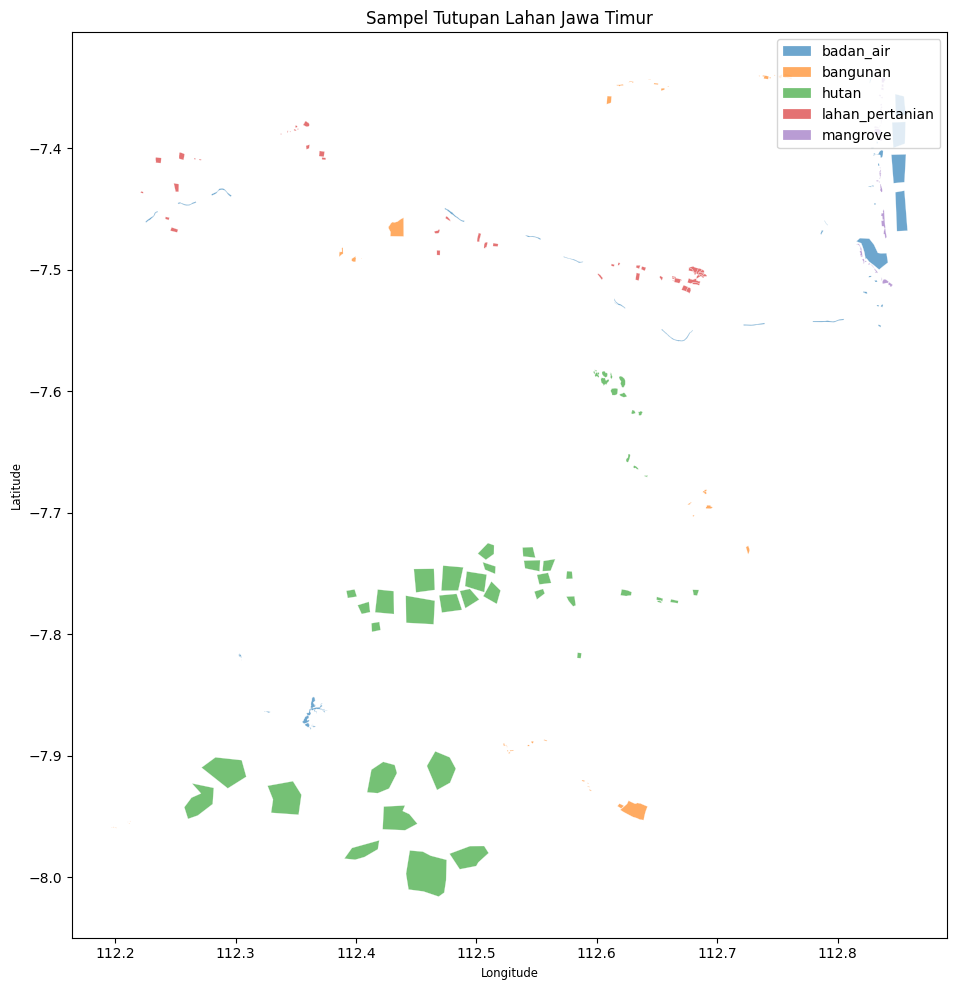

In [20]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))

samples.plot(
    ax=ax,
    column="class_name",
    categorical=True,
    legend=True,
    alpha=0.65,
    edgecolor="white",
    linewidth=0.25
)

ax.set_title("Sampel Tutupan Lahan Jawa Timur")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

## 8. Menyelaraskan raster B8A, B11, dan B04

Band B8A dan B11 umumnya memiliki resolusi 20 m, sedangkan B04 10 m. Untuk mengikuti kombinasi band yang diminta, notebook menyamakan semua band ke grid B8A (umumnya 20 m). Pastikan semua raster berasal dari tanggal/komposit dan area yang sama.

In [21]:
# Grid acuan = B8A. Reproject/resample B11 dan B04 ke grid yang sama.
with rasterio.open(band_paths["B8A"]) as ref:
    ref_profile = ref.profile.copy()
    ref_transform = ref.transform
    ref_crs = ref.crs
    height, width = ref.height, ref.width
    ref_bounds = ref.bounds
    ref_array = ref.read(1).astype("float32")
    ref_nodata = ref.nodata

def read_to_reference(path, ref_shape, ref_transform, ref_crs, resampling=Resampling.bilinear):
    dest = np.full(ref_shape, np.nan, dtype="float32")
    with rasterio.open(path) as src:
        src_arr = src.read(1).astype("float32")
        src_nodata = src.nodata
        if src_nodata is not None:
            src_arr[src_arr == src_nodata] = np.nan
        reproject(
            source=src_arr,
            destination=dest,
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=np.nan,
            dst_transform=ref_transform,
            dst_crs=ref_crs,
            dst_nodata=np.nan,
            resampling=resampling
        )
    return dest

if ref_nodata is not None:
    ref_array[ref_array == ref_nodata] = np.nan

arr_b8a = ref_array
arr_b11 = read_to_reference(band_paths["B11"], (height, width), ref_transform, ref_crs)
arr_b04 = read_to_reference(band_paths["B04"], (height, width), ref_transform, ref_crs)

# Feature order: exactly the requested band combination.
image = np.stack([arr_b8a, arr_b11, arr_b04], axis=-1)
FEATURE_NAMES = ["B8A", "B11", "B04"]

valid_pixels = np.all(np.isfinite(image), axis=-1)
print("Ukuran citra (baris, kolom, band):", image.shape)
print("CRS:", ref_crs, "| Bounds:", ref_bounds)
print("Piksel valid:", int(valid_pixels.sum()))

Ukuran citra (baris, kolom, band): (2500, 2364, 3)
CRS: EPSG:4326 | Bounds: BoundingBox(left=112.151054, bottom=-8.082351, right=112.870396, top=-7.328674)
Piksel valid: 5910000


## 9. Ekstraksi nilai spektral dari poligon training

In [22]:
# Raster dan GeoJSON harus overlap secara geografis.
samples_raster = samples.to_crs(ref_crs)

X_list, y_list, polygon_ids = [], [], []
for idx, row in samples_raster.reset_index(drop=True).iterrows():
    geom = row.geometry
    try:
        inside = geometry_mask(
            [mapping(geom)],
            out_shape=(height, width),
            transform=ref_transform,
            invert=True,
            all_touched=False
        )
        mask = inside & valid_pixels
        pixels = image[mask]
        if len(pixels):
            X_list.append(pixels)
            y_list.extend([row["class_name"]] * len(pixels))
            polygon_ids.extend([idx] * len(pixels))
    except Exception as e:
        print("Poligon dilewati:", idx, e)

if not X_list:
    raise ValueError(
        "Tidak ada piksel yang terekstrak. Periksa CRS, lokasi sampel, "
        "dan apakah raster mencakup sampel."
    )

X = np.vstack(X_list)
y = np.asarray(y_list)
polygon_ids = np.asarray(polygon_ids)

print("Jumlah piksel sampel:", len(y))
display(pd.Series(y).value_counts().reindex(CLASSES, fill_value=0).to_frame("jumlah_piksel"))
print("Fitur:", FEATURE_NAMES)

Jumlah piksel sampel: 111088


,jumlah_piksel
bangunan,5476
lahan_pertanian,4473
badan_air,15642
hutan,83699
mangrove,1798


Fitur: ['B8A', 'B11', 'B04']


## 10. Membagi data training dan testing

Notebook referensi menggunakan pembagian piksel train/test. Di sini digunakan pembagian **berdasarkan poligon** untuk mengurangi kebocoran data dari poligon yang sama ke kedua kelompok. Setiap kelas sebaiknya mempunyai beberapa poligon yang terpisah.

In [23]:
# Buat split pada ID poligon, lalu petakan ke piksel.
poly_table = samples_raster.reset_index(drop=True)[["class_name"]].copy()
poly_table["poly_id"] = poly_table.index

poly_counts = poly_table["class_name"].value_counts().reindex(CLASSES, fill_value=0)
display(poly_counts.to_frame("jumlah_poligon"))

if (poly_counts < 2).any():
    raise ValueError(
        "Setiap kelas harus memiliki minimal 2 poligon untuk split berbasis poligon. "
        "Tambahkan sampel digitasi untuk kelas yang kurang."
    )

train_poly_ids, test_poly_ids = train_test_split(
    poly_table["poly_id"].values,
    test_size=0.20,
    random_state=42,
    stratify=poly_table["class_name"]
)

train_mask = np.isin(polygon_ids, train_poly_ids)
test_mask = np.isin(polygon_ids, test_poly_ids)

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("Training pixels:", len(y_train))
print("Testing pixels:", len(y_test))
print("Kelas train:", pd.Series(y_train).value_counts().to_dict())
print("Kelas test:", pd.Series(y_test).value_counts().to_dict())

,jumlah_poligon
class_name,
bangunan,50
lahan_pertanian,49
badan_air,50
hutan,50
mangrove,50


Training pixels: 84879
Testing pixels: 26209
Kelas train: {'hutan': 67724, 'badan_air': 8548, 'bangunan': 3646, 'lahan_pertanian': 3455, 'mangrove': 1506}
Kelas test: {'hutan': 15975, 'badan_air': 7094, 'bangunan': 1830, 'lahan_pertanian': 1018, 'mangrove': 292}


## 11. Melatih Random Forest

In [24]:
rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)
print("Model Random Forest berhasil dilatih.")

Model Random Forest berhasil dilatih.


## 12. Evaluasi model

Overall accuracy: 0.5473
Kappa index: 0.301
Macro F1: 0.2702

Classification report:
                 precision    recall  f1-score   support

       bangunan       0.09      0.08      0.09      1830
lahan_pertanian       0.19      0.44      0.27      1018
      badan_air       0.08      0.02      0.03      7094
          hutan       0.95      0.84      0.89     15975
       mangrove       0.04      1.00      0.08       292

       accuracy                           0.55     26209
      macro avg       0.27      0.47      0.27     26209
   weighted avg       0.61      0.55      0.57     26209



,bangunan,lahan_pertanian,badan_air,hutan,mangrove
bangunan,149,1496,28,157,0
lahan_pertanian,64,449,123,357,25
badan_air,39,315,110,200,6430
hutan,1394,74,1163,13344,0
mangrove,0,0,0,0,292


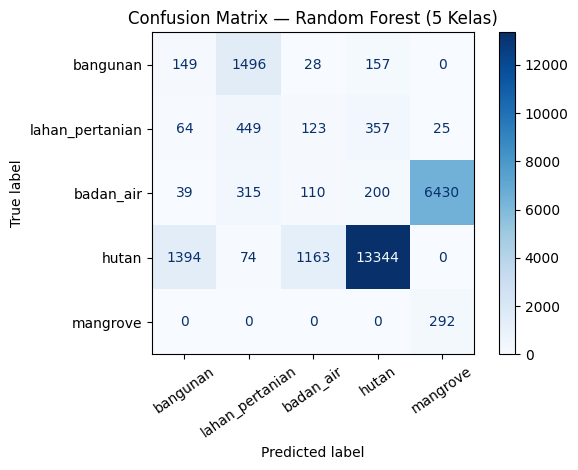

In [25]:
accuracy = accuracy_score(y_test, y_pred)
kappa = cohen_kappa_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

print("Overall accuracy:", round(accuracy, 4))
print("Kappa index:", round(kappa, 4))
print("Macro F1:", round(macro_f1, 4))
print("\nClassification report:")
print(classification_report(y_test, y_pred, labels=CLASSES, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=CLASSES)
cm_df = pd.DataFrame(cm, index=CLASSES, columns=CLASSES)
display(cm_df)

ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASSES).plot(
    cmap="Blues", xticks_rotation=35, values_format="d"
)
plt.title("Confusion Matrix — Random Forest (5 Kelas)")
plt.tight_layout()
plt.show()

cm_df.to_csv("/content/landcover_output/confusion_matrix.csv")

## 13. Membuat peta klasifikasi seluruh raster

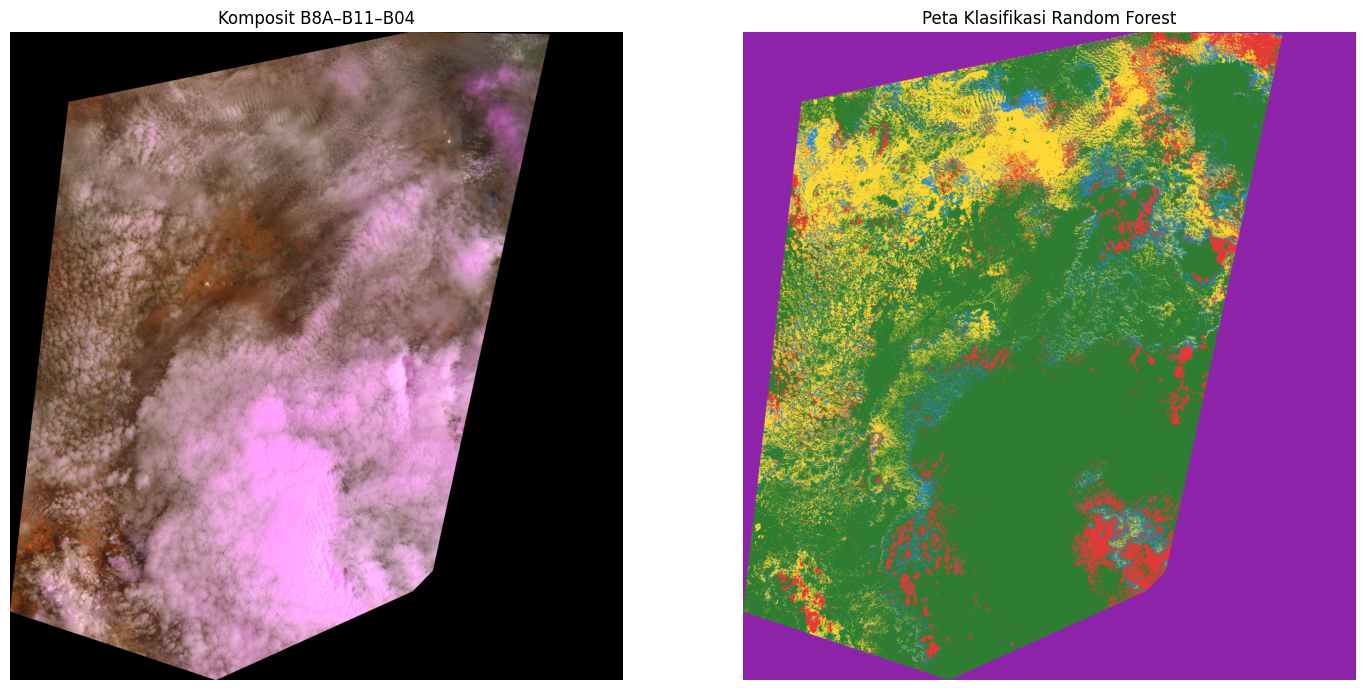

Warna kelas:
#e53935 = bangunan
#fdd835 = lahan_pertanian
#1e88e5 = badan_air
#2e7d32 = hutan
#8e24aa = mangrove


In [26]:
class_map = np.zeros((height, width), dtype=np.uint8)
if valid_pixels.any():
    class_map[valid_pixels] = rf.predict(image[valid_pixels]).astype(np.uint8) if False else 0
    # RandomForestClassifier belajar string label, jadi prediksi diubah ke ID kelas.
    pred_all = rf.predict(image[valid_pixels])
    class_map[valid_pixels] = np.array([CLASS_TO_ID[v] for v in pred_all], dtype=np.uint8)

# Visualisasi komposit 8A-11-4 (false-color composite).
rgb = np.stack([arr_b8a, arr_b11, arr_b04], axis=-1)
valid_rgb = np.all(np.isfinite(rgb), axis=-1)
rgb_show = np.zeros_like(rgb, dtype="float32")
if valid_rgb.any():
    lo = np.nanpercentile(rgb[valid_rgb], 2)
    hi = np.nanpercentile(rgb[valid_rgb], 98)
    rgb_show[valid_rgb] = np.clip((rgb[valid_rgb] - lo) / (hi - lo + 1e-9), 0, 1)

from matplotlib.colors import ListedColormap, BoundaryNorm
colors = ["#e53935", "#fdd835", "#1e88e5", "#2e7d32", "#8e24aa"]
cmap = ListedColormap(colors)
norm = BoundaryNorm(np.arange(0.5, len(CLASSES) + 1.5, 1), cmap.N)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
axes[0].imshow(rgb_show)
axes[0].set_title("Komposit B8A–B11–B04")
axes[0].axis("off")
axes[1].imshow(np.ma.masked_equal(class_map, 0), cmap=cmap, norm=norm)
axes[1].set_title("Peta Klasifikasi Random Forest")
axes[1].axis("off")
plt.tight_layout()
plt.show()

print("Warna kelas:")
for cls, color in zip(CLASSES, colors):
    print(color, "=", cls)

Keterangan Warna Kelas:
- Merah = bangunan
- Kuning = lahan_pertanian
- Biru = badan_air
- Hijau = hutan
- Ungu = mangrove

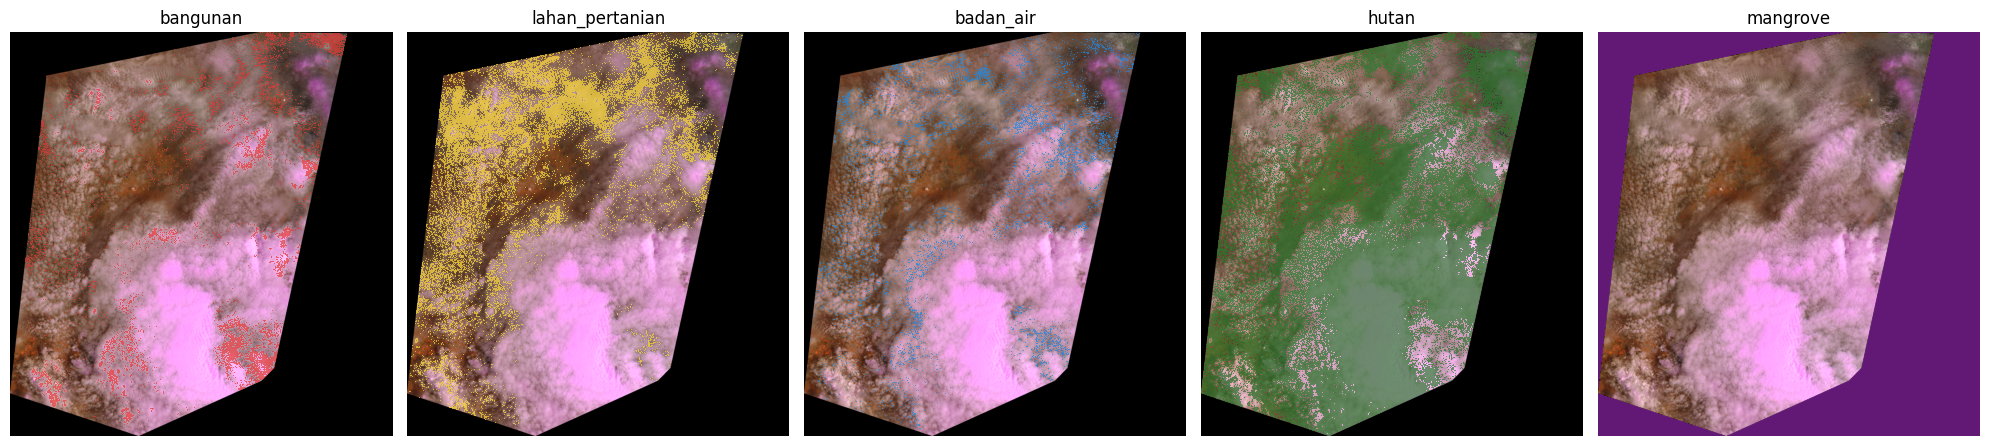

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

num_classes = len(CLASSES)
fig, axes = plt.subplots(1, num_classes, figsize=(4 * num_classes, 5))

if num_classes == 1:
    axes = [axes]

for idx, (cls_name, color) in enumerate(zip(CLASSES, colors)):
    class_id = idx + 1

    axes[idx].imshow(rgb_show)
    single_class_map = np.ma.masked_where(class_map != class_id, class_map)

    single_cmap = ListedColormap([color])
    axes[idx].imshow(single_class_map, cmap=single_cmap, alpha=0.7, interpolation='none')

    axes[idx].set_title(f"{cls_name}")
    axes[idx].axis("off")

plt.tight_layout()
plt.show()

## 14. Menyimpan peta klasifikasi ke GeoTIFF

In [27]:
out_profile = ref_profile.copy()
out_profile.update(
    driver="GTiff",
    count=1,
    dtype="uint8",
    nodata=0,
    compress="lzw"
)
out_tif = "/content/landcover_output/klasifikasi_tutupan_lahan_jatim.tif"

with rasterio.open(out_tif, "w", **out_profile) as dst:
    dst.write(class_map, 1)

print("Raster hasil disimpan:", out_tif)
print("Kode kelas:", CLASS_TO_ID)

Raster hasil disimpan: /content/landcover_output/klasifikasi_tutupan_lahan_jatim.tif
Kode kelas: {'bangunan': 1, 'lahan_pertanian': 2, 'badan_air': 3, 'hutan': 4, 'mangrove': 5}


## 15. Konversi hasil raster menjadi GeoJSON

In [28]:
# Polygonize raster kelas. Untuk raster besar, GeoJSON bisa menjadi sangat besar.
# Lakukan pada AOI kecil/area yang sesuai dan generalisasi jika perlu.
from shapely.geometry import shape

records = []
for geom, value in shapes(
    class_map,
    mask=(class_map > 0),
    transform=ref_transform
):
    cid = int(value)
    if cid in ID_TO_CLASS:
        records.append({
            "geometry": shape(geom),
            "class_id": cid,
            "class_name": ID_TO_CLASS[cid]
        })

result_gdf = gpd.GeoDataFrame(records, crs=ref_crs, geometry="geometry")
result_gdf = result_gdf.to_crs("EPSG:4326")

# Hitung luas menggunakan CRS proyeksi yang sesuai wilayah.
# Zona UTM harus dicek untuk lokasi AOI; EPSG:32749 cocok untuk sebagian Jawa Timur barat/selatan.
try:
    area_gdf = result_gdf.to_crs("EPSG:32749")
    result_gdf["area_ha"] = area_gdf.geometry.area / 10000
except Exception:
    result_gdf["area_ha"] = np.nan

result_gdf["model"] = "Random Forest"
result_gdf["bands"] = "B8A-B11-B04"

out_geojson = "/content/landcover_output/klasifikasi_tutupan_lahan_jatim.geojson"
result_gdf.to_file(out_geojson, driver="GeoJSON")
print("GeoJSON tersimpan:", out_geojson)
print("Jumlah poligon hasil:", len(result_gdf))
display(result_gdf.head())

GeoJSON tersimpan: /content/landcover_output/klasifikasi_tutupan_lahan_jatim.geojson
Jumlah poligon hasil: 257262


,geometry,class_id,class_name,area_ha,model,bands
0,"POLYGON ((112.61753 -7.32867, 112.61753 -7.328...",2,lahan_pertanian,0.112018,Random Forest,B8A-B11-B04
1,"POLYGON ((112.61784 -7.32867, 112.61784 -7.328...",5,mangrove,0.112018,Random Forest,B8A-B11-B04
2,"POLYGON ((112.61814 -7.32867, 112.61814 -7.328...",2,lahan_pertanian,0.336053,Random Forest,B8A-B11-B04
3,"POLYGON ((112.6221 -7.32867, 112.6221 -7.32898...",1,bangunan,0.112018,Random Forest,B8A-B11-B04
4,"POLYGON ((112.6227 -7.32867, 112.6227 -7.32898...",1,bangunan,0.112018,Random Forest,B8A-B11-B04


## 16. Statistik luas per kelas dan unduhan hasil

In [29]:
stats = (
    result_gdf.groupby("class_name", dropna=False)["area_ha"]
    .sum()
    .reindex(CLASSES, fill_value=0)
    .reset_index()
)
stats.columns = ["class_name", "area_ha"]
display(stats)

stats_path = "/content/landcover_output/statistik_luas_kelas.csv"
stats.to_csv(stats_path, index=False)

files.download(out_tif)
files.download(out_geojson)
files.download("/content/landcover_output/confusion_matrix.csv")
files.download(stats_path)

,class_name,area_ha
0,bangunan,33808.174417
1,lahan_pertanian,82567.691376
2,badan_air,25261.293300
3,hutan,286252.448935
4,mangrove,233502.628155


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>